<a href="https://colab.research.google.com/github/gmauricio-toledo/math-ML/blob/main/Notebooks/23-CNN_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1>Clasificación con Redes Neuronales Convolucionales</h1>

En esta notebook usaremos una red neuronal convolucional (CNN) para un problema de clasificación de imágenes, además, compararemos esta arquitectura con la arquitectura MLP.

<p align="center">
  <img src="https://drive.google.com/uc?id=1bzFBdsAq40yN95k2pA5X2OGsXf-40v0t" width="600" />
</p>

El CIFAR-10 (Canadian Institute For Advanced Research) es un conjunto de datos clásico en visión por computadora, compuesto por 60,000 imágenes en color (32x32 píxeles) distribuidas en 10 clases distintas: avión, automóvil, pájaro, gato, ciervo, perro, rana, caballo, barco y camión. Cada clase contiene 6,000 imágenes, con 5,000 para entrenamiento y 1,000 para prueba. Su tamaño reducido y su diversidad lo convierten en un benchmark ideal para comparar modelos de aprendizaje automático, especialmente en tareas de clasificación de imágenes. A diferencia de MNIST, donde las MLP pueden alcanzar altos rendimientos, CIFAR-10 presenta mayores desafíos debido a variaciones en iluminación, trasfondos y perspectivas, lo que resalta la ventaja de arquitecturas basadas en convoluciones (CNN).

Su objetivo principal es servir como punto de referencia para evaluar la capacidad de los modelos para generalizar características visuales jerárquicas y espaciales.

[Fuente oficial](https://www-cs-toronto-edu.translate.goog/~kriz/cifar.html?_x_tr_sl=en&_x_tr_tl=es&_x_tr_hl=es&_x_tr_pto=tc)

\\

| **Clase**  | **Descripción**       |  
|------------|-----------------------|  
| 0          | Avión (airplane)      |  
| 1          | Automóvil (automobile)|  
| 2          | Pájaro (bird)         |  
| 3          | Gato (cat)            |  
| 4          | Ciervo (deer)         |  
| 5          | Perro (dog)           |  
| 6          | Rana (frog)           |  
| 7          | Caballo (horse)       |  
| 8          | Barco (ship)          |  
| 9          | Camión (truck)        |  

Verifiquemos que el entorno de ejecución en Colab sea GPU

In [ ]:
import tensorflow as tf

print('GPU presente en: {}'.format(tf.test.gpu_device_name()))

GPU presente en: /device:GPU:0


In [ ]:
from tensorflow.keras.datasets import cifar10

(X_train, y_train), (X_test, y_test) = cifar10.load_data()

print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1320s 8us/step
X_train shape: (50000, 32, 32, 3)
y_train shape: (50000, 1)
X_test shape: (10000, 32, 32, 3)
y_test shape: (10000, 1)


🔵 Obervar que ahora, cada instancia en el dataset es un tensor 3-dimensional.

In [ ]:
classes_names = ['Avión', 'Automóvil', 'Pájaro', 'Gato', 'Ciervo', 'Perro', 'Rana', 'Caballo', 'Barco', 'Camión']

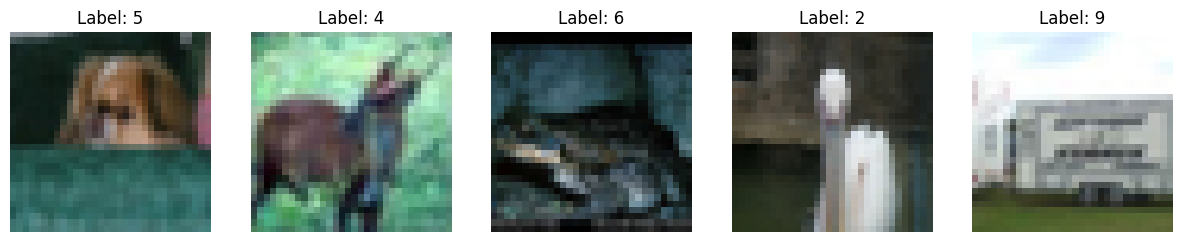

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

random_idxs = np.random.choice(range(X_train.shape[0]),size=5,replace=True)

fig, axs = plt.subplots(1,5,figsize=(15,5))
for i, idx in enumerate(random_idxs):
  axs[i].imshow(X_train[idx])
  axs[i].title.set_text(f'Label: {y_train[idx,0]}')
  axs[i].axis('off')
plt.show()

Veamos el balanceo de clases

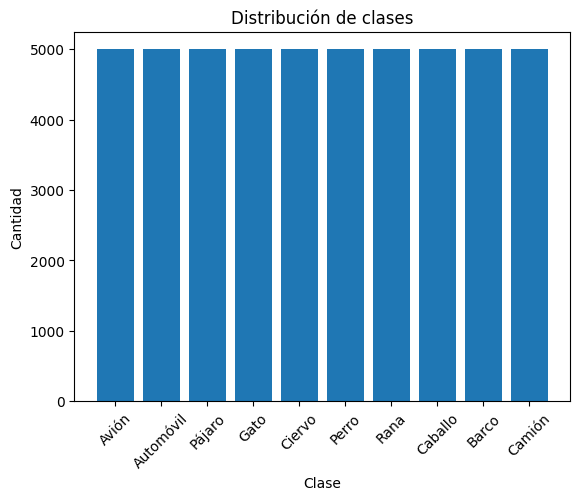

In [ ]:
import matplotlib.pyplot as plt

classes, countings = np.unique(y_train,return_counts=True)

plt.figure()
plt.bar(classes, countings)
plt.xlabel('Clase')
plt.ylabel('Cantidad')
plt.title('Distribución de clases')
plt.xticks(classes,labels=classes_names,rotation=45)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train,
                                                  stratify=y_train,
                                                  test_size=0.2,
                                                  random_state=42)

print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_val shape: {X_val.shape}")
print(f"y_val shape: {y_val.shape}")

X_train shape: (40000, 32, 32, 3)
y_train shape: (40000, 1)
X_val shape: (10000, 32, 32, 3)
y_val shape: (10000, 1)


Hacemos el preprocesamiento usual

In [ ]:
print(f"Rango de valores de X_train: {X_train.min()} - {X_train.max()}")
print(f"Rango de valores de X_val: {X_val.min()} - {X_val.max()}")
print(f"Rango de valores de X_test: {X_test.min()} - {X_test.max()}")

Rango de valores de X_train: 0 - 255
Rango de valores de X_val: 0 - 255
Rango de valores de X_test: 0 - 255


In [ ]:
X_train = X_train.astype('float32') / 255.0
X_val = X_val.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print(f"Rango de valores de X_train: {X_train.min()} - {X_train.max()}")
print(f"Rango de valores de X_val: {X_val.min()} - {X_val.max()}")
print(f"Rango de valores de X_test: {X_test.min()} - {X_test.max()}")

Rango de valores de X_train: 0.0 - 1.0
Rango de valores de X_val: 0.0 - 1.0
Rango de valores de X_test: 0.0 - 1.0


In [ ]:
from matplotlib import pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score
from seaborn import heatmap
import numpy as np

def plot_training_curves(history):
    plt.figure(figsize=(11,5))
    plt.subplot(1,2,1)
    plt.title("Validation and Training Loss",fontsize=14)
    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='validation')
    plt.legend()
    if len(history.history['loss']) < 10:
        plt.xticks(range(1,len(history.history['loss'])+1))
    plt.subplot(1,2,2)
    plt.title("Validation and Training Accuracy",fontsize=14)
    plt.plot(history.history['accuracy'], label='train')
    plt.plot(history.history['val_accuracy'], label='validation')
    plt.legend()
    if len(history.history['loss']) < 10:
        plt.xticks(range(1,len(history.history['accuracy'])+1))
    plt.show()

def evaluate(model,X,y):
    y_pred_proba = model.predict(X)
    y_pred = np.argmax(y_pred_proba,axis=1)
    print(f"Accuracy: {accuracy_score(y,y_pred)}")
    print(f"F1 Score: {f1_score(y,y_pred,average='macro')}")
    cm = confusion_matrix(y_pred=y_pred,y_true=y)
    plt.figure()
    heatmap(cm,
            fmt='g',
            annot=True,
            xticklabels=classes_names,
            yticklabels=classes_names)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

## Modelo MLP

Probemos dos modelos

In [ ]:
from keras.models import Sequential
from keras.layers import Dense, Flatten, Input, BatchNormalization, Dropout
from keras.optimizers import Adam

def build_model(input_shape,small=True):
    if small:
        model = Sequential()
        model.add(Input(shape=input_shape))
        model.add(Flatten())
        model.add(Dense(128, activation='relu'))
        model.add(BatchNormalization())
        model.add(Dense(64, activation='relu'))
        model.add(BatchNormalization())
        model.add(Dense(10, activation='softmax'))
        model.compile(optimizer=Adam(learning_rate=1e-4),
                    loss='sparse_categorical_crossentropy',
                    metrics=['accuracy'])
    else:
        model = Sequential()
        model.add(Input(shape=input_shape))
        model.add(Flatten())
        model.add(Dense(1024, activation='relu'))
        model.add(BatchNormalization())
        model.add(Dropout(0.3))
        model.add(Dense(512, activation='relu'))
        model.add(BatchNormalization())
        model.add(Dropout(0.3))
        model.add(Dense(256, activation='relu'))
        model.add(BatchNormalization())
        model.add(Dropout(0.2))
        model.add(Dense(10, activation='softmax'))
        model.compile(optimizer=Adam(learning_rate=1e-4),
                    loss='sparse_categorical_crossentropy',
                    metrics=['accuracy'])
    return model

###  MLP 1

In [ ]:
model_mlp_1 = build_model((32,32,3),small=True)
model_mlp_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 403,018 (1.54 MB)

 Trainable params: 402,634 (1.54 MB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2,
                              patience=3, min_lr=1e-6)

early_stopping = EarlyStopping(monitor='val_loss',
                               patience=5,
                               restore_best_weights=True)

⌚ El entrenamiento tarda alrededor de 2 minutos

In [ ]:
history = model_mlp_1.fit(X_train, y_train,
                        batch_size=64,
                        epochs=100,
                        validation_data=(X_val, y_val),
                        callbacks=[reduce_lr, early_stopping])

Epoch 1/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.3348 - loss: 1.9052 - val_accuracy: 0.3573 - val_loss: 1.8984 - learning_rate: 1.0000e-04
Epoch 2/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4080 - loss: 1.6762 - val_accuracy: 0.3968 - val_loss: 1.7331 - learning_rate: 1.0000e-04
Epoch 3/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4385 - loss: 1.5954 - val_accuracy: 0.4152 - val_loss: 1.6831 - learning_rate: 1.0000e-04
Epoch 4/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.4588 - loss: 1.5475 - val_accuracy: 0.4250 - val_loss: 1.6479 - learning_rate: 1.0000e-04
Epoch 5/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.4725 - loss: 1.5036 - val_accuracy: 0.3935 - val_loss: 1.7225 - learning_rate: 1.0000e-04
Epoch 6/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4824 - loss: 1.4764 - val_accuracy: 0.4467 - val_loss: 1.6005 - learning_rate: 1.0000e-04
Epoch 7/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - acc

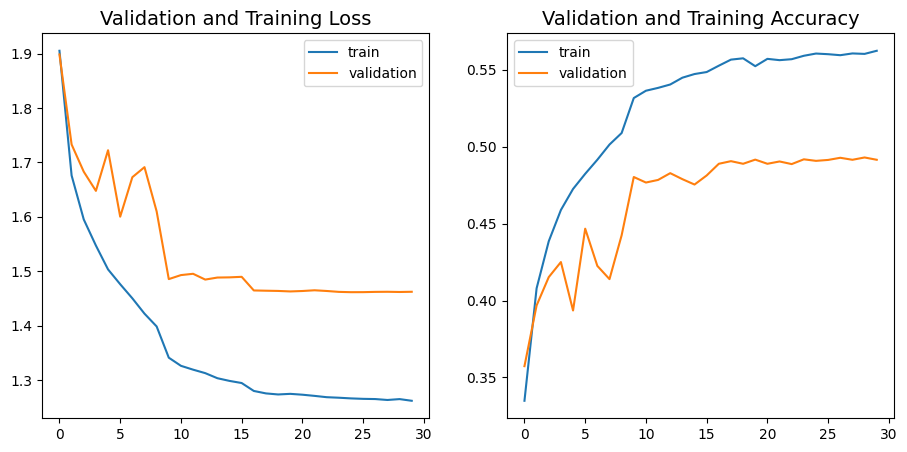

In [ ]:
plot_training_curves(history)

🔵 En estas curvas es muy notorio la acción del callback `ReduceLROnPlateau`.

Evaluemos el modelo en el conjunto de prueba

In [ ]:
model_mlp_1.evaluate(X_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4897 - loss: 1.4453


[1.4453009366989136, 0.48969998955726624]

Hagamos una evaluación más detallada

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Accuracy: 0.4897
F1 Score: 0.486343396344711


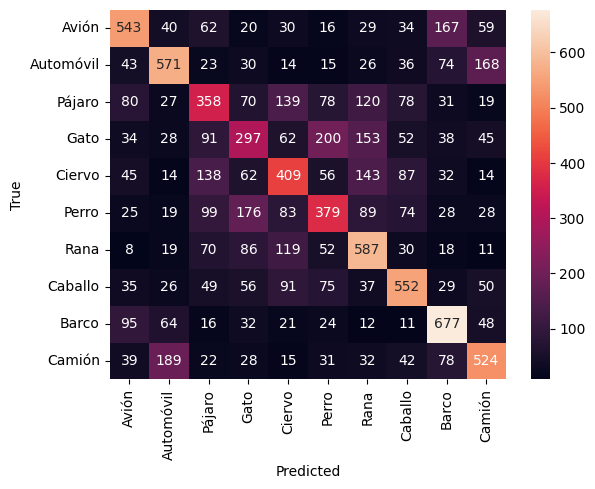

In [ ]:
evaluate(model_mlp_1,X_test,y_test)

### MLP 2

Probemos con una arquitectura MLP más compleja (observa el número de capas, tamaño y número total de parámetros)

In [ ]:
model_mlp_2 = build_model((32,32,3),small=False)
model_mlp_2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1024)           │     3,146,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,812,618 (14.54 MB)

 Trainable params: 3,809,034 (14.53 MB)

 Non-trainable params: 3,584 (14.00 KB)

🔵 Observa que estamos usando los mismos callbacks inicializados del entrenamiento pasado. ¿Es esto correcto?

⌚ Este entrenamiento tarda alrededor de 4 minutos con GPU

In [ ]:
history = model_mlp_2.fit(X_train, y_train,
                        batch_size=64,
                        epochs=100,
                        validation_data=(X_val, y_val),
                        callbacks=[reduce_lr, early_stopping])

Epoch 1/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.2895 - loss: 2.1718 - val_accuracy: 0.3786 - val_loss: 1.8225 - learning_rate: 1.0000e-04
Epoch 2/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.3506 - loss: 1.8959 - val_accuracy: 0.4119 - val_loss: 1.6729 - learning_rate: 1.0000e-04
Epoch 3/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.3768 - loss: 1.7972 - val_accuracy: 0.3999 - val_loss: 1.7207 - learning_rate: 1.0000e-04
Epoch 4/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.4020 - loss: 1.7121 - val_accuracy: 0.4613 - val_loss: 1.5370 - learning_rate: 2.0000e-05
Epoch 5/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4140 - loss: 1.6748 - val_accuracy: 0.4669 - val_loss: 1.5163 - learning_rate: 2.0000e-05


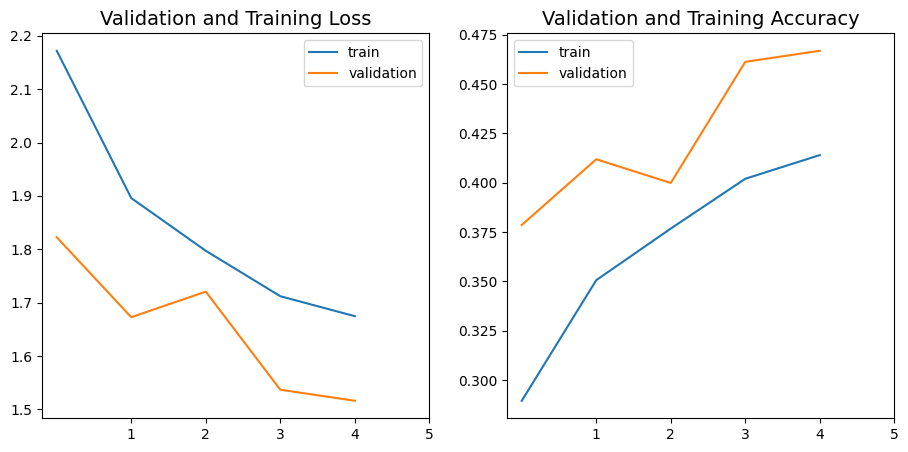

In [ ]:
plot_training_curves(history)

Tenemos un mejor entrenamiento y un desempeño ligeramente superior

In [ ]:
model_mlp_2.evaluate(X_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3919 - loss: 1.7868


[1.7867963314056396, 0.3919000029563904]

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Accuracy: 0.3919
F1 Score: 0.36818498383091225


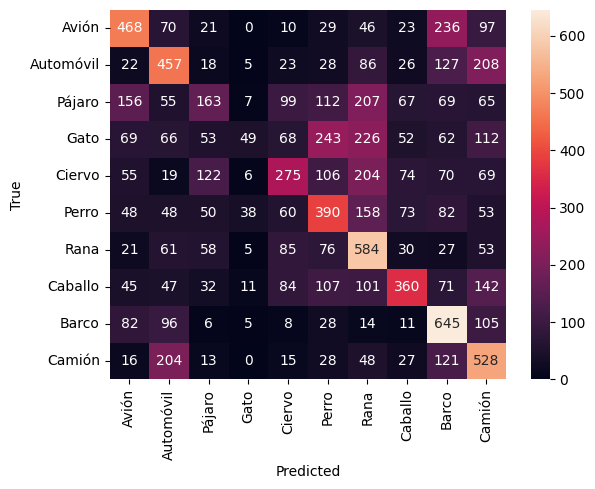

In [ ]:
evaluate(model_mlp_2,X_test,y_test)

## Modelo CNN

Definamos ahora un modelo con arquitectura CNN. Usaremos las capas [`Conv2D`](https://keras.io/api/layers/convolution_layers/convolution2d/) para las operaciones de convolución y [`MaxPooling2D`](https://keras.io/api/layers/pooling_layers/max_pooling2d/) para el pooling.

<p align="center">
  <img src="https://drive.google.com/uc?id=1bzFBdsAq40yN95k2pA5X2OGsXf-40v0t" width="600" />
</p>


**Importante**: Observa la elección de los hiperparámetros `padding="same"` y `strides=1`. Esta elección asegura que las salidas de cada capa convolucional tenga las mismas dimensiones que las entradas.

### Modelo 1

In [ ]:
from keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Input
from keras.models import Sequential

model_cnn = Sequential()
model_cnn.add(Input(shape=(32, 32, 3)))
#----- PARTE CONVOLUCIONAL -------
model_cnn.add(Conv2D(32, 3, activation='relu',
                     padding="same",
                     strides=1))
model_cnn.add(MaxPooling2D())
model_cnn.add(Conv2D(64, 3, activation='relu',
                     padding="same", # Probemos comentando esta línea
                     strides=1))
model_cnn.add(MaxPooling2D())
model_cnn.add(Conv2D(128, 3, activation='relu',
                     padding="same",
                     strides=1))
model_cnn.add(MaxPooling2D())
#----- PARTE MLP ----------
model_cnn.add(Flatten())
model_cnn.add(Dense(512, activation='relu'))
model_cnn.add(Dense(10, activation='softmax'))  # recordar que esta capa está fija por el problema

model_cnn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,147,466 (4.38 MB)

 Trainable params: 1,147,466 (4.38 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from keras.optimizers import Adam

model_cnn.compile(optimizer=Adam(learning_rate=1e-4),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

⌚ El entrenamiento tarda alrededor de 3 minutos

In [ ]:
history = model_cnn.fit(X_train, y_train,
                        batch_size=64,
                        epochs=100,
                        validation_data=(X_val, y_val),
                        callbacks=[reduce_lr, early_stopping])

Epoch 1/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 14ms/step - accuracy: 0.3658 - loss: 1.7655 - val_accuracy: 0.4669 - val_loss: 1.5097 - learning_rate: 1.0000e-04
Epoch 2/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.4927 - loss: 1.4186 - val_accuracy: 0.5272 - val_loss: 1.3445 - learning_rate: 1.0000e-04
Epoch 3/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5441 - loss: 1.2907 - val_accuracy: 0.5531 - val_loss: 1.2623 - learning_rate: 1.0000e-04
Epoch 4/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5777 - loss: 1.2010 - val_accuracy: 0.5839 - val_loss: 1.1944 - learning_rate: 1.0000e-04
Epoch 5/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6033 - loss: 1.1302 - val_accuracy: 0.6137 - val_loss: 1.1235 - learning_rate: 1.0000e-04
Epoch 6/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6203 - loss: 1.0785 - val_accuracy: 0.6117 - val_loss: 1.0994 - learning_rate: 1.0000e-04
Epoch 7/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - 

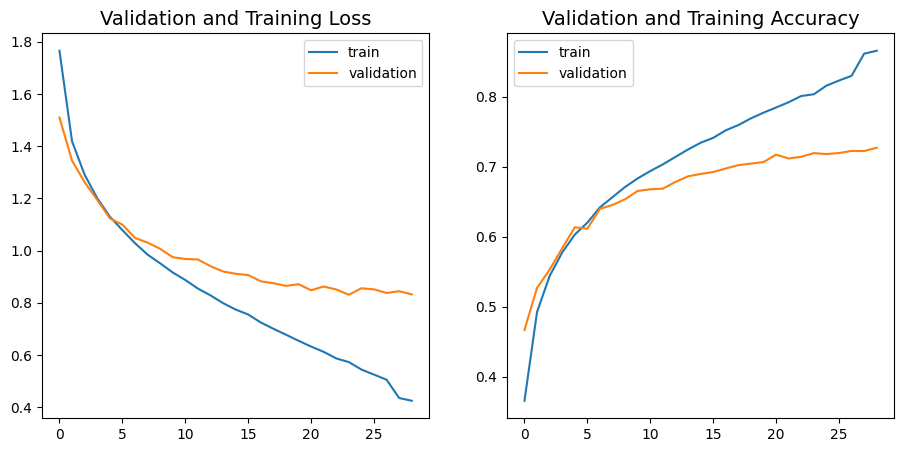

In [ ]:
plot_training_curves(history)

In [ ]:
model_cnn.evaluate(X_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7191 - loss: 0.8277


[0.8276533484458923, 0.7190999984741211]

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
Accuracy: 0.7191
F1 Score: 0.7194337281924891


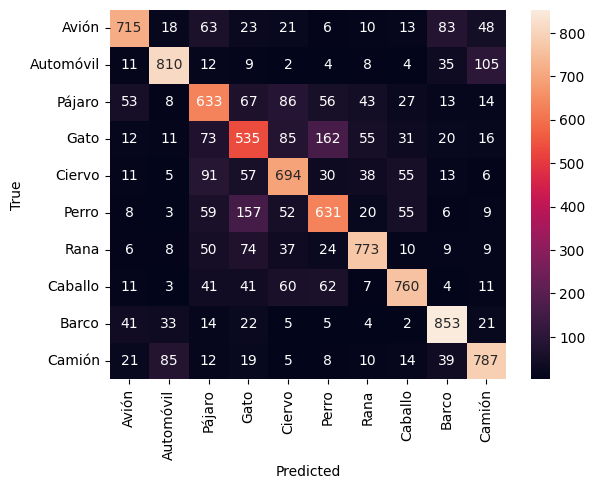

In [ ]:
evaluate(model_cnn,X_test,y_test)

🔵 Observar que tenemos un rendimiento muy superior con esta red CNN al modelo MLP 2, aún cuando el MLP es más grande que el CNN (3.8 millones de parámetros vs 1.1 millones de parámetros). Esto exhibe el hecho de que las redes CNN son arquitecturas especialidas en problemas relacionados con imágenes.

### Modelo 2

In [ ]:
import keras
from keras import layers, models

model_vgg = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    # Data Augmentation en GPU (se desactiva automáticamente en inferencia/validación)
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1),

    # Bloque 1: 32x32 -> 16x16
    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(momentum=0.9),
    layers.Activation("relu"),
    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(momentum=0.9),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.2),

    # Bloque 2: 16x16 -> 8x8
    layers.Conv2D(128, 3, padding="same", use_bias=False),
    layers.BatchNormalization(momentum=0.9),
    layers.Activation("relu"),
    layers.Conv2D(128, 3, padding="same", use_bias=False),
    layers.BatchNormalization(momentum=0.9),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.3),

    # Bloque 3: 8x8 -> 4x4
    layers.Conv2D(256, 3, padding="same", use_bias=False),
    layers.BatchNormalization(momentum=0.9),
    layers.Activation("relu"),
    layers.Conv2D(256, 3, padding="same", use_bias=False),
    layers.BatchNormalization(momentum=0.9),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.4),

    # Cabeza ligera (evita el sobreajuste del Flatten -> Dense(512))
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, use_bias=False),
    layers.BatchNormalization(momentum=0.9),
    layers.Activation("relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

In [ ]:
import keras
from keras import callbacks, optimizers

# 1. Compilación
model_vgg.compile(
    optimizer=optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 2. Callbacks para exprimir la convergencia
cb_list = [
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True,
        verbose=1
    )
]


In [ ]:
model_vgg.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 256)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 256)      │       589,82

 Total params: 1,217,226 (4.64 MB)

 Trainable params: 1,214,922 (4.63 MB)

 Non-trainable params: 2,304 (9.00 KB)

El entrenamiento tardó alrededor de 21 minutos

In [ ]:
history = model_vgg.fit(
    X_train, y_train,
    batch_size=128,
    epochs=100,
    validation_data=(X_val, y_val), # Corregido: y_val en lugar de y_test
    callbacks=cb_list
)

Epoch 1/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 64ms/step - accuracy: 0.3950 - loss: 1.6933 - val_accuracy: 0.4509 - val_loss: 1.7057 - learning_rate: 0.0010
Epoch 2/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 18s 57ms/step - accuracy: 0.5662 - loss: 1.2043 - val_accuracy: 0.5874 - val_loss: 1.1934 - learning_rate: 0.0010
Epoch 3/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 18s 58ms/step - accuracy: 0.6395 - loss: 1.0154 - val_accuracy: 0.6616 - val_loss: 0.9567 - learning_rate: 0.0010
Epoch 4/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 18s 57ms/step - accuracy: 0.6849 - loss: 0.8947 - val_accuracy: 0.5695 - val_loss: 1.4812 - learning_rate: 0.0010
Epoch 5/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 18s 57ms/step - accuracy: 0.7159 - loss: 0.8122 - val_accuracy: 0.6317 - val_loss: 1.1640 - learning_rate: 0.0010
Epoch 6/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 18s 56ms/step - accuracy: 0.7404 - loss: 0.7440 - val_accuracy: 0.7334 - val_loss: 0.7705 - learning_rate: 0.0010
Epoch 7/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 21s 57ms/step - accuracy: 0.7

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
Accuracy: 0.9039
F1 Score: 0.9032009345968062


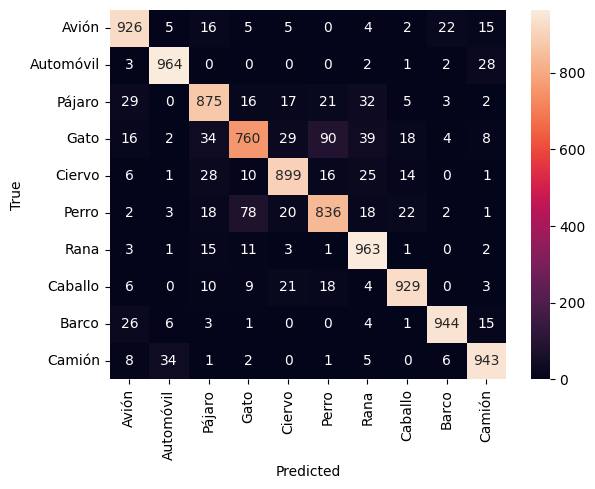

In [ ]:
evaluate(model_vgg,X_test,y_test)

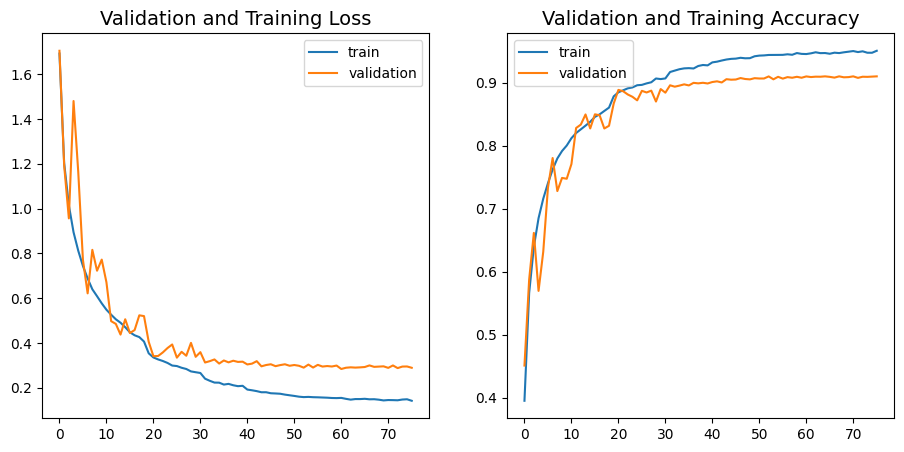

In [ ]:
plot_training_curves(history)

In [ ]:
model_vgg.save('cifar10-best_model_cnn.keras')

## Transfer Learning con MobileNetV2

Vamos a usar MobileNetV2 preentrenado en ImageNet. Primero congelaremos la base para usarla como extractor de características.

Tenemos que resolver un par de detalles:

1. Re-escalamos los valores de entrada de `[0, 1]` a `[-1, 1]`.
2. Hacemos un *Resize* de las imágenes a 96x96 antes de pasarlas a MobileNetV2.

### Modelo 1

In [ ]:
from keras.applications import MobileNetV2
from keras import layers, models, optimizers

# 1. Cargamos el modelo base pero esta vez para el tamaño 96x96
base_model_fixed = MobileNetV2(weights='imagenet',
                               include_top=False,
                               input_shape=(96, 96, 3))

base_model_fixed.trainable = False

# 2. Construimos el modelo con las capas de corrección
model_tl_fixed = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    # CORRECCIÓN 1: Convertir de rango [0, 1] a [-1, 1]
    layers.Rescaling(scale=2.0, offset=-1.0),

    # CORRECCIÓN 2: Redimensionar de 32x32 a 96x96
    layers.Resizing(96, 96, interpolation="bilinear"),

    # Modelo base
    base_model_fixed,

    # Cabeza de clasificación
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model_tl_fixed.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_tl_fixed.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,589,514 (9.88 MB)

 Trainable params: 331,018 (1.26 MB)

 Non-trainable params: 2,258,496 (8.62 MB)

In [ ]:
# 3. Entrenamos el modelo corregido
history_tl_fixed = model_tl_fixed.fit(
    X_train, y_train,
    batch_size=128,
    epochs=15,
    validation_data=(X_val, y_val),
    callbacks=cb_list
)

Epoch 1/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 64s 130ms/step - accuracy: 0.7969 - loss: 0.6291 - val_accuracy: 0.8520 - val_loss: 0.4245 - learning_rate: 0.0010
Epoch 2/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.8535 - loss: 0.4328 - val_accuracy: 0.8565 - val_loss: 0.4116 - learning_rate: 0.0010
Epoch 3/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.8686 - loss: 0.3859 - val_accuracy: 0.8651 - val_loss: 0.3936 - learning_rate: 0.0010
Epoch 4/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.8754 - loss: 0.3603 - val_accuracy: 0.8666 - val_loss: 0.3814 - learning_rate: 0.0010
Epoch 5/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8864 - loss: 0.3316
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.8838 - loss: 0.3393 - val_accuracy: 0.8617 - val_loss: 0.4016 - learning_rate: 0.0010
Epoch 6/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.8948 - loss: 0

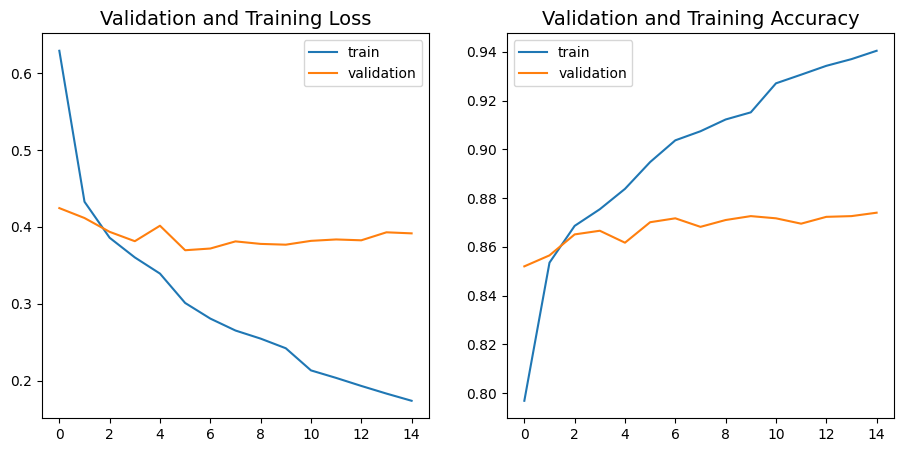

313/313 ━━━━━━━━━━━━━━━━━━━━ 21s 20ms/step
Accuracy: 0.8525
F1 Score: 0.8526641371426494


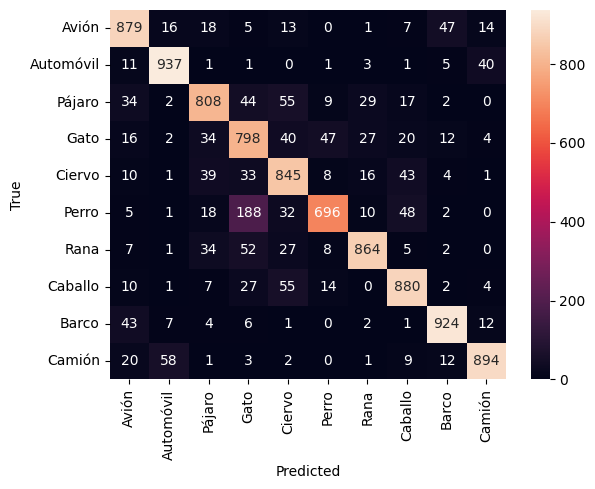

In [ ]:
plot_training_curves(history_tl_fixed)
evaluate(model_tl_fixed, X_test, y_test)

### Modelo 2: Fine-Tuning

Descongelamos el modelo base para que sus pesos se ajusten específicamente a las imágenes de CIFAR-10. Es fundamental recompilar el modelo con una tasa de aprendizaje mucho menor.

In [ ]:
from keras.applications import MobileNetV2
from keras import layers, models, optimizers
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

# 1. Cargamos el modelo base pero esta vez para el tamaño 96x96

base_model_fixed = MobileNetV2(weights='imagenet',
                               include_top=False,
                               input_shape=(96, 96, 3))

# 1. Descongelamos el modelo base
base_model_fixed.trainable = True

# Por completitud y claridad, esta es la arquitectura exacta que estamos afinando.
# NOTA: No redefinimos el objeto 'model_tl_fixed' con código activo porque eso reiniciaría
# los pesos de las capas Densas, perdiendo el entrenamiento del paso anterior.
model_ft = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    # Preprocesamiento
    layers.Rescaling(scale=2.0, offset=-1.0),
    layers.Resizing(96, 96, interpolation="bilinear"),

    # Modelo base
    base_model_fixed,  # <--- AHORA ESTÁ DESCONGELADO (trainable = True)

    # Cabeza de clasificación (con los pesos que ya pre-entrenamos)
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])


cb_list = [
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True,
        verbose=1
    )
]

# 2. Recompilamos el modelo (obligatorio después de cambiar el atributo trainable)
# Usamos un learning rate MUY pequeño (1e-5) para no destruir los pesos preentrenados
model_ft.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_ft.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing_1 (Resizing)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,589,514 (9.88 MB)

 Trainable params: 2,554,890 (9.75 MB)

 Non-trainable params: 34,624 (135.25 KB)

El entrenamiento duro 12 minutos

In [ ]:
# 3. Entrenamos (Ajuste Fino)
# Podemos usar los mismos callbacks, el early stopping nos protegerá del sobreajuste
history_fine_tuning = model_ft.fit(
    X_train, y_train,
    batch_size=128,
    epochs=20,
    validation_data=(X_val, y_val),
    callbacks=cb_list
)

Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 137s 230ms/step - accuracy: 0.7740 - loss: 0.7473 - val_accuracy: 0.7799 - val_loss: 0.8039 - learning_rate: 1.0000e-04
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 54s 87ms/step - accuracy: 0.9188 - loss: 0.2472 - val_accuracy: 0.8683 - val_loss: 0.4116 - learning_rate: 1.0000e-04
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 27s 86ms/step - accuracy: 0.9525 - loss: 0.1418 - val_accuracy: 0.8815 - val_loss: 0.3885 - learning_rate: 1.0000e-04
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 26s 83ms/step - accuracy: 0.9712 - loss: 0.0847 - val_accuracy: 0.8843 - val_loss: 0.4096 - learning_rate: 1.0000e-04
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 26s 84ms/step - accuracy: 0.9833 - loss: 0.0528 - val_accuracy: 0.8894 - val_loss: 0.3999 - learning_rate: 1.0000e-04
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 27s 86ms/step - accuracy: 0.9866 - loss: 0.0384 - val_accuracy: 0.8953 - val_loss: 0.4052 - learning_rate: 1.0000e-04
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 27s 85ms/s

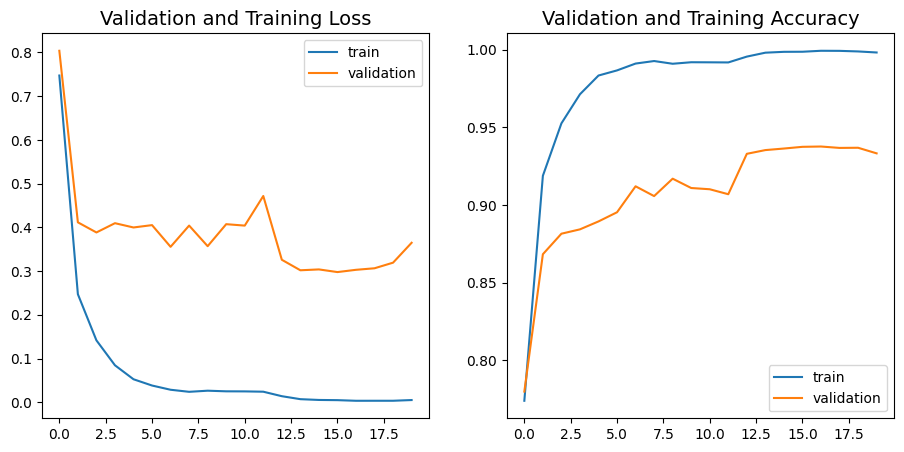

313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step
Accuracy: 0.9344
F1 Score: 0.9341825238465595


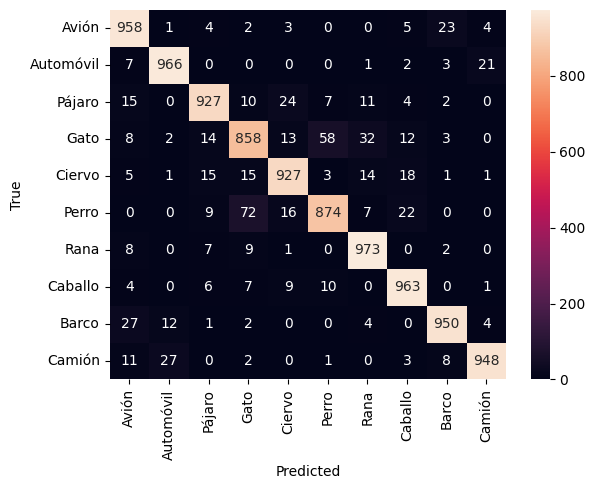

In [ ]:
plot_training_curves(history_fine_tuning)
evaluate(model_ft, X_test, y_test)

In [ ]:
model_tl_fixed.save('cifar10-imagenet-finetuned.keras')

### Comparativa de Rendimiento de los Modelos

A continuación, visualizamos el rendimiento final (Accuracy en el conjunto de prueba) de los 6 modelos evaluados a lo largo de este cuaderno para contrastar sus resultados.

Preparando datos para ML clásico (aplanando imágenes)...
Reduciendo dimensionalidad con PCA...
Entrenando Random Forest...
Evaluando Random Forest...
Evaluando MLP Simple...
Evaluando MLP Complejo...
Evaluando CNN Básica...
Evaluando CNN avanzada...
Evaluando MobileNetV2 (TL)...
Evaluando MobileNetV2 (FT)...


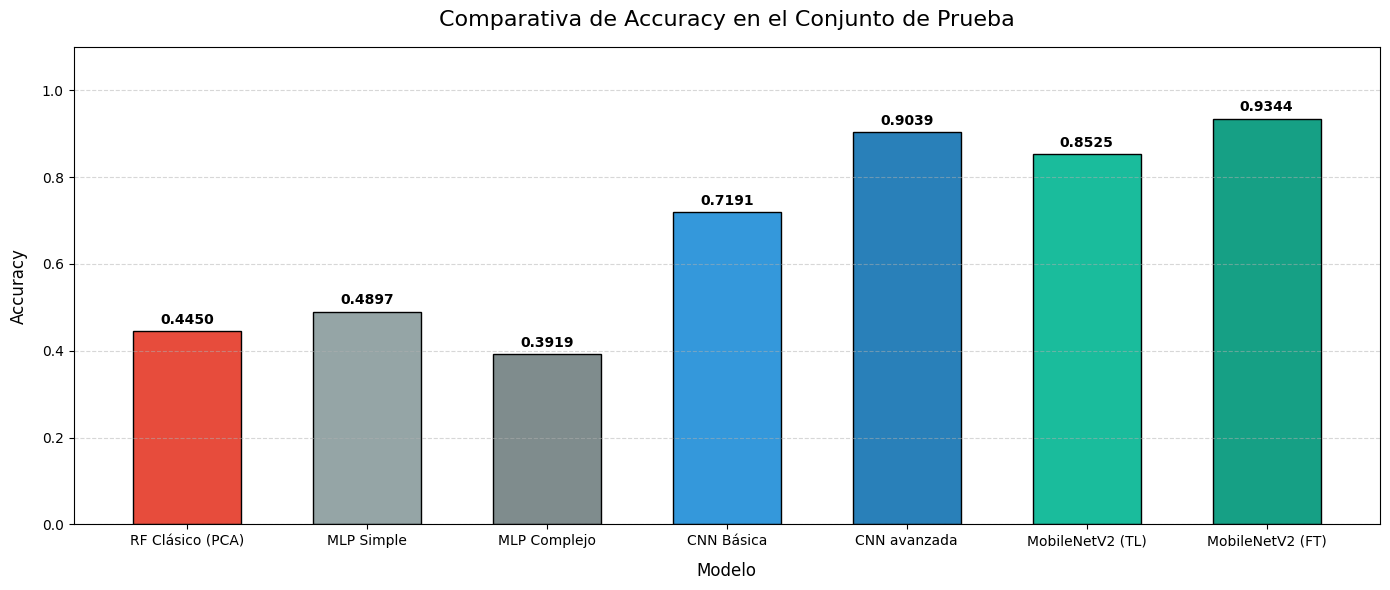

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA

# 1. Entrenar y evaluar un clasificador de Machine Learning clásico de forma rápida
print("Preparando datos para ML clásico (aplanando imágenes)...")
# Aplanamos las imágenes para el clasificador clásico
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

print("Reduciendo dimensionalidad con PCA...")
pca = PCA(n_components=50, random_state=42)
X_train_pca = pca.fit_transform(X_train_flat)
X_test_pca = pca.transform(X_test_flat)

print("Entrenando Random Forest...")
rf_clf = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf_clf.fit(X_train_pca, y_train.ravel())

print("Evaluando Random Forest...")
acc_rf = rf_clf.score(X_test_pca, y_test.ravel())

# 2. Obtener las accuracies evaluando dinámicamente cada modelo de Deep Learning
print("Evaluando MLP Simple...")
loss_mlp1, acc_mlp1 = model_mlp_1.evaluate(X_test, y_test, verbose=0)

print("Evaluando MLP Complejo...")
loss_mlp2, acc_mlp2 = model_mlp_2.evaluate(X_test, y_test, verbose=0)

print("Evaluando CNN Básica...")
loss_cnn, acc_cnn = model_cnn.evaluate(X_test, y_test, verbose=0)

print("Evaluando CNN avanzada...")
loss_vgg, acc_vgg = model_vgg.evaluate(X_test, y_test, verbose=0)

print("Evaluando MobileNetV2 (TL)...")
loss_tl, acc_tl = model_tl_fixed.evaluate(X_test, y_test, verbose=0)

print("Evaluando MobileNetV2 (FT)...")
loss_ft, acc_ft = model_ft.evaluate(X_test, y_test, verbose=0)

# Definir los nombres de los modelos y las accuracies obtenidas
modelos = [
    'RF Clásico (PCA)',
    'MLP Simple',
    'MLP Complejo',
    'CNN Básica',
    'CNN avanzada',
    'MobileNetV2 (TL)',
    'MobileNetV2 (FT)'
]

accuracies = [acc_rf, acc_mlp1, acc_mlp2, acc_cnn, acc_vgg, acc_tl, acc_ft]

# 3. Graficar los resultados
plt.figure(figsize=(14, 6))
colores = ['#e74c3c', '#95a5a6', '#7f8c8d', '#3498db', '#2980b9', '#1abc9c', '#16a085']

bars = plt.bar(modelos, accuracies, color=colores, edgecolor='black', width=0.6)

# Añadir etiquetas con el valor exacto encima de cada barra
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.01, f"{yval:.4f}", ha='center', va='bottom', fontweight='bold')

plt.title('Comparativa de Accuracy en el Conjunto de Prueba', fontsize=16, pad=15)
plt.xlabel('Modelo', fontsize=12, labelpad=10)
plt.ylabel('Accuracy', fontsize=12, labelpad=10)
plt.ylim(0, 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()